In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
print("Python", __import__("sys").version.split()[0], "| pandas", pd.__version__, "| NumPy", np.__version__,
      "| Matplotlib", matplotlib.__version__, "| seaborn", sns.__version__)
os.makedirs("../data/processed", exist_ok=True)
os.makedirs("../images", exist_ok=True)

df = pd.read_csv(r"C:\hclpython\hospital_data (1).csv")
df.head()

Python 3.15.1 | pandas 3.1.1 | NumPy 2.5.5 | Matplotlib 3.11.2 | seaborn 0.13.2


,Appointment_ID,Appointment_Date,City,Department,Booking_Mode,Insurance_Status,Patient_Age,Waiting_Time_Min,Consultation_Duration_Min,Consultation_Fee_INR,Patient_Satisfaction_Score
0,A1125,2025-01-20,Mumbai,General Medicine,Online,Self-Pay,41.0,54.0,17,350.0,7.2
1,A1056,2026-07-29,Delhi,Pediatrics,Walk-in,Insured,2.0,34.0,18,350.0,8.2
2,A1051,2025-04-22,Mumbai,Cardiology,Online,Insured,49.0,33.0,16,1050.0,6.9
3,A1220,2026-02-20,Delhi,Orthopaedics,Online,Self-Pay,NaN,5.0,10,700.0,7.9
4,A1152,2026-10-17,Pune,General Medicine,Walk-in,Insured,73.0,31.0,21,500.0,7.2


In [ ]:
print("Rows and columns:", df.shape)
print()
df.info()
df.isnull().sum()   
print("Duplicate rows:", df.duplicated().sum())
df.describe()
df["City"].value_counts()


Rows and columns: (255, 11)

<class 'pandas.DataFrame'>
RangeIndex: 255 entries, 0 to 254
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Appointment_ID              255 non-null    str    
 1   Appointment_Date            255 non-null    str    
 2   City                        255 non-null    str    
 3   Department                  255 non-null    str    
 4   Booking_Mode                250 non-null    str    
 5   Insurance_Status            255 non-null    str    
 6   Patient_Age                 250 non-null    float64
 7   Waiting_Time_Min            249 non-null    float64
 8   Consultation_Duration_Min   255 non-null    int64  
 9   Consultation_Fee_INR        251 non-null    float64
 10  Patient_Satisfaction_Score  255 non-null    float64
dtypes: float64(4), int64(1), str(6)
memory usage: 22.0 KB
Duplicate rows: 5


City
Mumbai         64
Delhi          64
Bengaluru      55
Lucknow        39
Pune           26
Bengaluru       1
DELHI           1
 Delhi          1
lucknow         1
MUMBAI          1
delhi           1
mumbai          1
Name: count, dtype: int64

In [3]:
clean = df.copy()
rows_before = len(clean)

clean = clean.drop_duplicates()
print("Duplicates removed:", rows_before - len(clean))
print("Rows now:", len(clean))

Duplicates removed: 5
Rows now: 250


In [4]:
clean["City"] = clean["City"].str.strip().str.title()
clean["City"].value_counts()
bad_age = (clean["Patient_Age"] < 0) | (clean["Patient_Age"] > 100)
print("Impossible ages found:", bad_age.sum())
clean.loc[bad_age, "Patient_Age"] = np.nan


Impossible ages found: 2


In [5]:
clean["Patient_Age"] = clean["Patient_Age"].fillna(clean["Patient_Age"].median())
clean["Waiting_Time_Min"] = clean["Waiting_Time_Min"].fillna(clean["Waiting_Time_Min"].median())
clean["Consultation_Fee_INR"] = clean.groupby("Department")["Consultation_Fee_INR"] \
                                     .transform(lambda s: s.fillna(s.median()))
clean["Booking_Mode"] = clean["Booking_Mode"].fillna(clean["Booking_Mode"].mode()[0])
clean["Appointment_Date"] = pd.to_datetime(clean["Appointment_Date"])

print("Blank cells left:",clean.isnull().sum().sum())
print("Rows after cleaning:", len(clean))
print("Age range now:", clean["Patient_Age"].min(), "to", clean["Patient_Age"].max())


Blank cells left: 0
Rows after cleaning: 250
Age range now: 1.0 to 85.0


In [6]:
clean["Wait_To_Consult_Ratio"] = (clean["Waiting_Time_Min"] / clean["Consultation_Duration_Min"]).round(2)
clean["Risk_Status"] = np.where(clean["Patient_Satisfaction_Score"] < 6.0, "At Risk", "OK")
clean["Age_Group"] = pd.cut(clean["Patient_Age"], bins=[0, 14, 39, 59, 200],
                            labels=["0-14", "15-39", "40-59", "60+"])
clean[["Waiting_Time_Min", "Consultation_Duration_Min", "Wait_To_Consult_Ratio",
       "Patient_Satisfaction_Score", "Risk_Status", "Age_Group"]].head()

,Waiting_Time_Min,Consultation_Duration_Min,Wait_To_Consult_Ratio,Patient_Satisfaction_Score,Risk_Status,Age_Group
0,54.0,17,3.18,7.2,OK,40-59
1,34.0,18,1.89,8.2,OK,0-14
2,33.0,16,2.06,6.9,OK,40-59
3,5.0,10,0.50,7.9,OK,15-39
4,31.0,21,1.48,7.2,OK,60+


In [7]:
score = clean["Patient_Satisfaction_Score"]
print("Mean  :", round(score.mean(), 2))
print("Median:", score.median())
print("Std   :", round(score.std(), 2))
print("Min / Max:", score.min(), "/", score.max())
print("Scores below 6.0:", (score < 6).sum(), "of", len(score), "=", round((score < 6).mean() * 100), "%")
print("Scores 8 or more:", round((score >= 8).mean() * 100), "%")

Mean  : 7.06
Median: 7.0
Std   : 1.42
Min / Max: 3.8 / 10.0
Scores below 6.0: 60 of 250 = 24 %
Scores 8 or more: 26 %


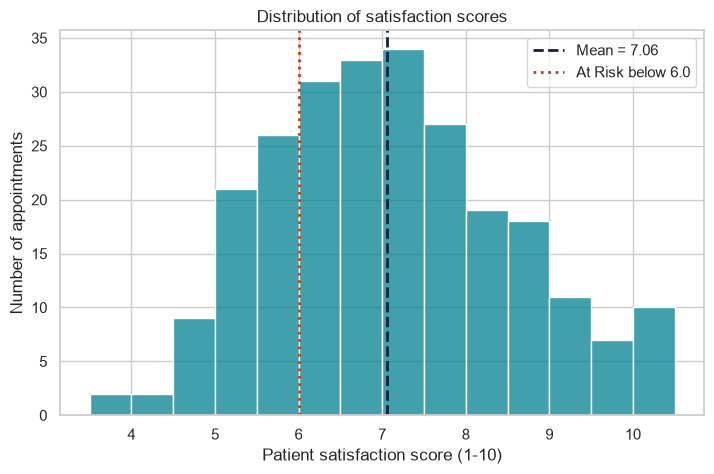

In [8]:
plt.figure(figsize=(7.3, 4.9))
sns.histplot(score, bins=np.arange(3.5, 10.6, 0.5), color="#028090")
plt.axvline(score.mean(), color="#14213D", linestyle="--", linewidth=2, label=f"Mean = {score.mean():.2f}")
plt.axvline(6, color="#C2410C", linestyle=":", linewidth=2, label="At Risk below 6.0")
plt.title("Distribution of satisfaction scores")
plt.xlabel("Patient satisfaction score (1-10)")
plt.ylabel("Number of appointments")
plt.legend()
plt.tight_layout()
plt.savefig("../images/q1_distribution.png", dpi=200)
plt.show()

In [9]:
num_cols = ["Patient_Age", "Waiting_Time_Min", "Consultation_Duration_Min", "Consultation_Fee_INR"]
corr = clean[num_cols].corrwith(clean["Patient_Satisfaction_Score"]).round(2)
corr

Patient_Age                 -0.05
Waiting_Time_Min            -0.46
Consultation_Duration_Min    0.46
Consultation_Fee_INR        -0.07
dtype: float64

In [10]:
wait = clean["Waiting_Time_Min"]
print("Average score, wait up to 30 min:", round(score[wait <= 30].mean(), 1), "(", (wait <= 30).sum(), "visits )")
print("Average score, wait over 45 min :", round(score[wait > 45].mean(), 1), "(", (wait > 45).sum(), "visits )")

Average score, wait up to 30 min: 7.9 ( 92 visits )
Average score, wait over 45 min : 6.2 ( 45 visits )


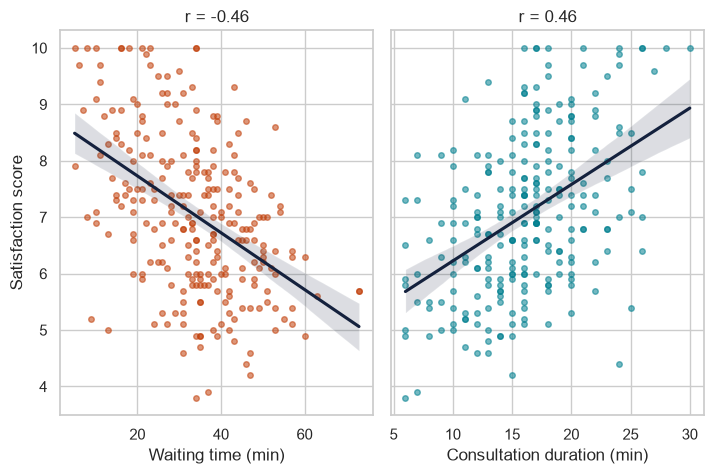

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(7.3, 4.9), sharey=True)
sns.regplot(data=clean, x="Waiting_Time_Min", y="Patient_Satisfaction_Score", ax=axes[0],
            scatter_kws={"s": 16, "alpha": 0.55, "color": "#C2410C"}, line_kws={"color": "#14213D"})
axes[0].set_title(f"r = {corr['Waiting_Time_Min']}")
axes[0].set_xlabel("Waiting time (min)")
axes[0].set_ylabel("Satisfaction score")

sns.regplot(data=clean, x="Consultation_Duration_Min", y="Patient_Satisfaction_Score", ax=axes[1],
            scatter_kws={"s": 16, "alpha": 0.55, "color": "#028090"}, line_kws={"color": "#14213D"})
axes[1].set_title(f"r = {corr['Consultation_Duration_Min']}")
axes[1].set_xlabel("Consultation duration (min)")
axes[1].set_ylabel("")

plt.tight_layout()
plt.savefig("../images/q2_wait_duration.png", dpi=200)
plt.show()

In [12]:
for col in ["Booking_Mode", "Department", "City", "Insurance_Status"]:
    print(clean.groupby(col)["Patient_Satisfaction_Score"].mean().round(2).sort_values(ascending=False))
    print()

Booking_Mode
Online     7.46
Phone      7.00
Walk-in    6.50
Name: Patient_Satisfaction_Score, dtype: float64

Department
General Medicine    7.19
Orthopaedics        7.01
Pediatrics          7.00
Cardiology          6.86
Name: Patient_Satisfaction_Score, dtype: float64

City
Delhi        7.12
Mumbai       7.12
Lucknow      7.09
Pune         6.96
Bengaluru    6.92
Name: Patient_Satisfaction_Score, dtype: float64

Insurance_Status
Self-Pay    7.24
Insured     6.95
Name: Patient_Satisfaction_Score, dtype: float64



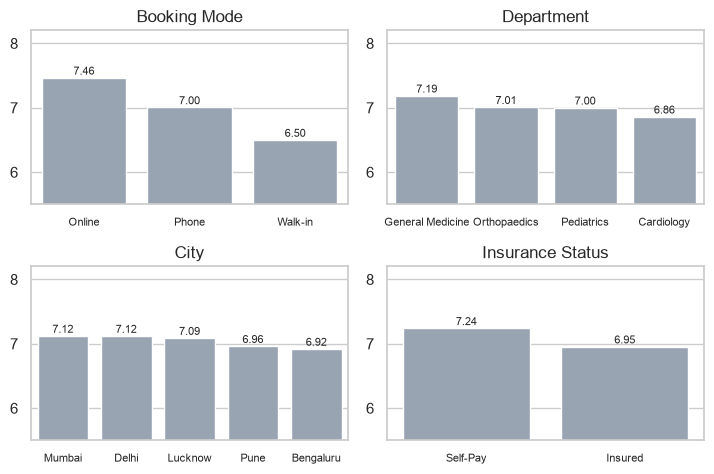

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(7.3, 4.9))
for ax, col in zip(axes.ravel(), ["Booking_Mode", "Department", "City", "Insurance_Status"]):
    order = clean.groupby(col)["Patient_Satisfaction_Score"].mean().sort_values(ascending=False).index
    sns.barplot(data=clean, x=col, y="Patient_Satisfaction_Score", order=order,
                errorbar=None, color="#94A3B8", ax=ax)
    ax.set_ylim(5.5, 8.2)
    ax.set_title(col.replace("_", " "))
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="x", labelsize=8)
    for bar in ax.patches:
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.05,
                f"{bar.get_height():.2f}", ha="center", fontsize=8)
plt.tight_layout()
plt.savefig("../images/q3_groups.png", dpi=200)
plt.show()

In [14]:
at_risk = clean[clean["Risk_Status"] == "At Risk"]
print("At Risk visits:", len(at_risk), "=", round(len(at_risk) / len(clean) * 100), "% of all visits")

# Compare At Risk and OK visits
clean.groupby("Risk_Status")[["Waiting_Time_Min", "Consultation_Duration_Min", "Wait_To_Consult_Ratio"]].mean().round(1)

At Risk visits: 60 = 24 % of all visits


,Waiting_Time_Min,Consultation_Duration_Min,Wait_To_Consult_Ratio
Risk_Status,,,
At Risk,40.2,13.3,3.4
OK,31.3,17.0,2.0


In [15]:
risk_by_mode = clean.groupby("Booking_Mode")["Risk_Status"].apply(lambda s: (s == "At Risk").mean() * 100).round(1)
risk_by_mode

Booking_Mode
Online     14.4
Phone      20.6
Walk-in    40.8
Name: Risk_Status, dtype: float64

In [16]:
high_ratio = clean["Wait_To_Consult_Ratio"] > 3
print("At Risk when ratio > 3 :", round((clean.loc[high_ratio, "Risk_Status"] == "At Risk").mean() * 100), "%")
print("At Risk when ratio <= 3:", round((clean.loc[~high_ratio, "Risk_Status"] == "At Risk").mean() * 100), "%")
clean.groupby("Age_Group", observed=True)["Risk_Status"].apply(lambda s: (s == "At Risk").mean() * 100).round(1)

At Risk when ratio > 3 : 58 %
At Risk when ratio <= 3: 16 %


Age_Group
0-14     25.4
15-39    22.6
40-59    22.1
60+      28.6
Name: Risk_Status, dtype: float64

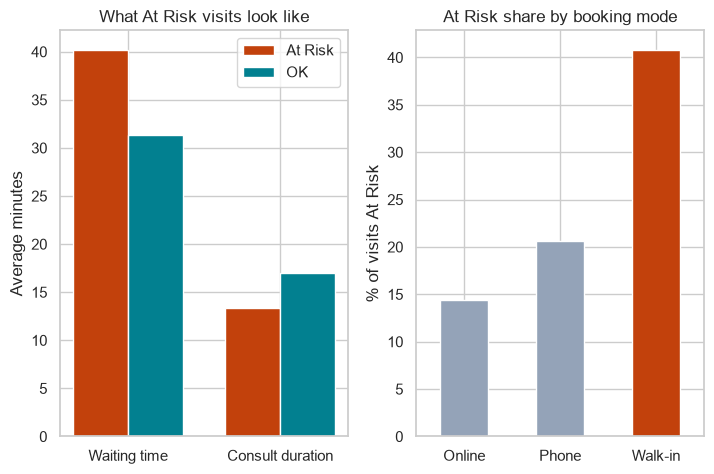

In [17]:
means = clean.groupby("Risk_Status")[["Waiting_Time_Min", "Consultation_Duration_Min"]].mean()

fig, axes = plt.subplots(1, 2, figsize=(7.3, 4.9))

x = np.arange(2)
axes[0].bar(x - 0.18, means.loc["At Risk"].values, 0.36, color="#C2410C", label="At Risk")
axes[0].bar(x + 0.18, means.loc["OK"].values, 0.36, color="#028090", label="OK")
axes[0].set_xticks(x)
axes[0].set_xticklabels(["Waiting time", "Consult duration"])
axes[0].set_ylabel("Average minutes")
axes[0].set_title("What At Risk visits look like")
axes[0].legend()

risk_by_mode.sort_values().plot(kind="bar", ax=axes[1], color=["#94A3B8", "#94A3B8", "#C2410C"])
axes[1].set_ylabel("% of visits At Risk")
axes[1].set_xlabel("")
axes[1].set_title("At Risk share by booking mode")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.savefig("../images/q4_at_risk.png", dpi=200)
plt.show()

In [18]:
clean.to_csv("C:\\hclpython\\hospital_clean_data (1).csv", index=False)
print("Saved. Rows:", len(clean), "Columns:", clean.shape[1])

Saved. Rows: 250 Columns: 14
